# Issue #268 — historical proxy backfill completeness

This executable notebook profiles the complete 808-issue candidate. Raw Nowscore/Titan bytes remain external origin evidence; SQLite is the durable normalized ingestion/QA store and Parquet is its #236-compatible analysis view. No outcome, settlement, winning-SP, payout or 0.65 factor is consumed.

In [1]:
from pathlib import Path
import json, os, sqlite3
import matplotlib.pyplot as plt
import pandas as pd

repo = Path.cwd()
data_root = Path(os.environ.get('BJ268_DATA_ROOT', repo / 'data')).expanduser().resolve()
package = data_root / 'derived/bj268/eu_proxy_backfill_v2'
database = package / 'candidate.sqlite'
verification_path = package / 'VERIFICATION.json'
assert database.is_file() and verification_path.is_file(), (database, verification_path)
verification = json.loads(verification_path.read_text(encoding='utf-8'))
verification['verdict'], database

('PASS',
 PosixPath('/home/drwho1985/workspace/soccer/beijing-lot/data/derived/bj268/eu_proxy_backfill_v2/candidate.sqlite'))

## Coverage by frozen source lane

In [2]:
coverage = pd.DataFrame(verification['coverage_by_lane'])
coverage['coverage_pct'] = 100 * coverage.covered_fixtures / coverage.inventory_fixtures
coverage

,reconciled_source,inventory_fixtures,covered_fixtures,unavailable_fixtures,coverage_pct
0,ACCEPTED_236,192709,192443,266,99.861968
1,AVAILABLE_EXTENSION,6001,6000,1,99.983336
2,NOWSCORE_ISSUE_PAGE,14553,14551,2,99.986257


PosixPath('/home/drwho1985/beijing-lot-268/docs/research/figures/issue-268-proxy-coverage.png')

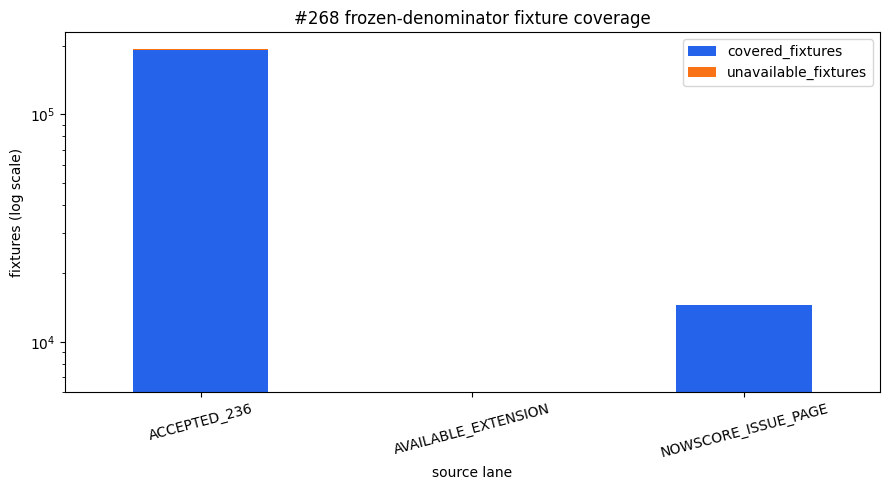

In [3]:
figure_dir = repo / 'docs/research/figures'
figure_dir.mkdir(parents=True, exist_ok=True)
ax = coverage.set_index('reconciled_source')[['covered_fixtures', 'unavailable_fixtures']].plot.bar(
    stacked=True, figsize=(9, 5), color=['#2563eb', '#f97316']
)
ax.set_title('#268 frozen-denominator fixture coverage')
ax.set_ylabel('fixtures (log scale)')
ax.set_yscale('log')
ax.set_xlabel('source lane')
ax.tick_params(axis='x', rotation=15)
ax.figure.tight_layout()
figure_path = figure_dir / 'issue-268-proxy-coverage.png'
ax.figure.savefig(figure_path, dpi=160)
figure_path

## Explicit unavailable fixtures outside the accepted #236 lane

In [4]:
with sqlite3.connect(database) as connection:
    unavailable = pd.read_sql_query('''
    WITH valid AS (
      SELECT DISTINCT m.issue, m.match_idx
      FROM matches m JOIN market_snapshots s ON s.match_id=m.match_id
      WHERE s.v1>1 AND s.v2>1 AND s.v3>1
    )
    SELECT i.issue_code, i.match_idx, i.provider_match_id, i.reconciled_source,
           COUNT(s.snapshot) AS raw_quote_rows
    FROM inventory i
    LEFT JOIN valid v ON v.issue=i.issue_code AND v.match_idx=i.match_idx
    LEFT JOIN matches m ON m.issue=i.issue_code AND m.match_idx=i.match_idx
    LEFT JOIN market_snapshots s ON s.match_id=m.match_id
    WHERE v.issue IS NULL AND i.reconciled_source <> 'ACCEPTED_236'
    GROUP BY i.issue_code, i.match_idx, i.provider_match_id, i.reconciled_source
    ORDER BY CAST(i.issue_code AS INTEGER), i.match_idx
    ''', connection)
unavailable

,issue_code,match_idx,provider_match_id,reconciled_source,raw_quote_rows
0,25053,442,2776635,NOWSCORE_ISSUE_PAGE,45
1,25091,217,2776165,NOWSCORE_ISSUE_PAGE,45
2,26051,331,2924541,AVAILABLE_EXTENSION,45


## Contract checks and downstream conclusion

In [5]:
assert verification['verdict'] == 'PASS'
assert verification['sqlite_counts']['issues'] == 808
assert verification['sqlite_counts']['fixtures'] == 213_263
assert verification['accepted_236_exact_parity'] is True
assert verification['parquet_hash_mismatches'] == 0
assert verification['forbidden_outcome_columns'] == []
assert coverage.inventory_fixtures.sum() == 213_263
assert coverage.unavailable_fixtures.sum() == 269
decision = {
    'denominator': 'COMPLETE_808_ISSUES',
    'fixture_inventory': 213_263,
    'probability_covered_fixtures': 212_994,
    'explicitly_unavailable_fixtures': 269,
    'newly_recovered_lane_coverage': '14,551 / 14,553 (99.986%)',
    'accepted_236_exact_parity': True,
    'causal_grade': 'RETROSPECTIVE_RELATIVE_PROXY',
}
decision

{'denominator': 'COMPLETE_808_ISSUES',
 'fixture_inventory': 213263,
 'probability_covered_fixtures': 212994,
 'explicitly_unavailable_fixtures': 269,
 'newly_recovered_lane_coverage': '14,551 / 14,553 (99.986%)',
 'accepted_236_exact_parity': True,
 'causal_grade': 'RETROSPECTIVE_RELATIVE_PROXY'}